# M5 Forecasting Accuracy: EDA

## Validation strategy

All data comes from `sales_train_evaluation.csv`, split by day.
Splits are always chronological: the model never sees days after the period
it is forecasting, which prevents data leakage. Days are never split at random.

| Period | Days | Role |
|---|---|---|
| Training | `d_1` – `d_1913` | Fit the model during development |
| Validation | `d_1914` – `d_1941` | Measure WRMSSE on known sales |
| Evaluation | `d_1942` – `d_1969` | Final forecast (sales unknown) |

The work runs in two stages:

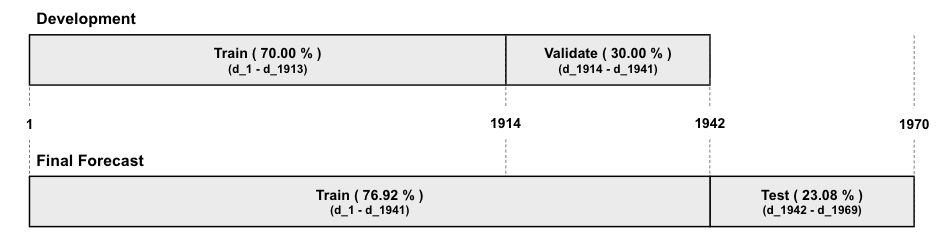

1. **Development.** Train on `d_1` – `d_1913` and forecast `d_1914` – `d_1941`.
   Compare the forecast with actual sales to compute WRMSSE.
   Feature and parameter changes are judged on this score.
2. **Final forecast.** Retrain on all data up to `d_1941` with the chosen setup,
   then forecast `d_1942` – `d_1969`. The most recent 28 days are the closest
   to the forecast period, so they are included in the final training.

Before training, each table is joined into one row per product, store and day:

- `sales_train_evaluation.csv` is reshaped from wide to long format
  (one column per day becomes one row per day).
- `calendar.csv` is joined on `d`.
- `sell_prices.csv` is joined on `store_id`, `item_id` and `wm_yr_wk`.
  Rows with no price are dropped, since the product was not yet on sale.

**Possible improvement:** A single 28-day window may fall on an unusual period.
Walk-forward validation over several windows (for example, ending at `d_1885`,
`d_1913` and `d_1941`) would give a more reliable estimate.

## 1. Import Libraries

In [26]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

## 2. Load Sales Data

In [27]:
sales_df = pd.read_csv("m5-data/sales_train_evaluation.csv")
sales_df.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


## 3. Sales EDA

### 3.1 Structure: 30,490 rows × 1,947 columns
- 1 แถว = สินค้า 1 รายการใน 1 ร้าน (3,049 items × 10 stores = 30,490)
- 6 columns แรกเป็น ID: `id`, `item_id`, `dept_id`, `cat_id`, `store_id`, `state_id`
- `d_1` – `d_1941` คือยอดขายรายวัน รวม 1,941 columns

In [28]:
sales_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Columns: 1947 entries, id to d_1941
dtypes: int64(1941), str(6)
memory usage: 452.9 MB


### 3.2 Melt `d_1` – `d_1941` into long format
- `d` ใช้สำหรับ join กับ `calendar.csv`
- `day` เป็นตัวเลขของวัน ใช้เรียงลำดับเวลา
- แปลง ID columns เป็น `category` เพื่อลด RAM เพราะตารางมีราว 59 ล้านแถว

In [29]:
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
sales_df[id_cols] = sales_df[id_cols].astype("category")

long_df = sales_df.melt(id_vars=id_cols, var_name="d", value_name="sales")
long_df["day"] = long_df["d"].str[2:].astype(int)
long_df.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,day
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1


In [30]:
long_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59181090 entries, 0 to 59181089
Data columns (total 9 columns):
 #   Column    Dtype   
---  ------    -----   
 0   id        category
 1   item_id   category
 2   dept_id   category
 3   cat_id    category
 4   store_id  category
 5   state_id  category
 6   d         str     
 7   sales     int64   
 8   day       int64   
dtypes: category(6), int64(2), str(1)
memory usage: 1.8 GB


ทุกวันมี 30,490 แถวเท่ากัน แปลว่าสินค้าทุกรายการมีแถวครบทุกวัน
รวมถึงช่วงก่อนเริ่มวางขาย ซึ่งยอดขายเป็น 0 แถวเหล่านี้จะถูกตัดออกตอน join กับ `sell_prices.csv`

In [31]:
long_df.groupby("day").size().agg(["min", "max"])

min    30490
max    30490
dtype: int64

## 4. Calendar EDA

In [32]:
calendar_df = pd.read_csv("m5-data/calendar.csv", parse_dates=["date"])
calendar_df.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [33]:
calendar_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1969 non-null   datetime64[us]
 1   wm_yr_wk      1969 non-null   int64         
 2   weekday       1969 non-null   str           
 3   wday          1969 non-null   int64         
 4   month         1969 non-null   int64         
 5   year          1969 non-null   int64         
 6   d             1969 non-null   str           
 7   event_name_1  162 non-null    str           
 8   event_type_1  162 non-null    str           
 9   event_name_2  5 non-null      str           
 10  event_type_2  5 non-null      str           
 11  snap_CA       1969 non-null   int64         
 12  snap_TX       1969 non-null   int64         
 13  snap_WI       1969 non-null   int64         
dtypes: datetime64[us](1), int64(7), str(6)
memory usage: 215.5 KB


### 4.1 `event_name_2` สามารถตัดออกได้ เพราะ

- มีข้อมูลเพียง 5 วัน จากทั้งหมด 1,969 วัน (น้อยกว่า 0.25%)
  ซึ่งเป็นวันที่มีอีเวนต์สองรายการตรงกันโดยบังเอิญ
- อีเวนต์ทุกรายการใน `event_name_2` ปรากฏใน `event_name_1` ในปีอื่นอยู่แล้ว
  โมเดลจึงยังเรียนรู้ผลของอีเวนต์เหล่านั้นได้จาก `event_name_1`
- ข้อมูลที่มีเพียงไม่กี่วัน ไม่พอให้โมเดลเรียนรู้รูปแบบได้อย่างน่าเชื่อถือ
  และยังเพิ่มคอลัมน์ที่ต้องใช้ RAM ในตารางราว 59 ล้านแถว

In [34]:
event_counts = (
    calendar_df[["event_name_1", "event_name_2"]]
    .melt(var_name="column", value_name="event")
    .dropna()
    .groupby(["event", "column"], observed=True)
    .size()
    .reset_index(name="days")
)

order = event_counts.groupby("event")["days"].sum().sort_values().index.tolist()

fig = px.bar(
    event_counts,
    x="days", y="event", color="column",
    orientation="h",
    category_orders={"event": order},
    title="Event days by column",
    labels={"days": "Number of days", "event": "", "column": ""},
    height=800,
)
fig.show()

In [35]:
n = calendar_df["event_name_2"].notna().sum()
print(n, f"{n / len(calendar_df):.2%}")

# เช็กว่าอีเวนต์ใน event_name_2 มีอยู่ใน event_name_1 ทั้งหมดหรือไม่
set(calendar_df["event_name_2"].dropna()) - set(calendar_df["event_name_1"].dropna())

5 0.25%


set()

In [36]:
calendar_df = calendar_df[[
    "d", "date", "wm_yr_wk", "wday", "month", "year",
    "event_name_1", "event_type_1", "snap_CA", "snap_TX", "snap_WI",
]]

# ลดขนาด dtype ก่อน join กับตาราง 59 ล้านแถว
for c in ["event_name_1", "event_type_1"]:
    calendar_df[c] = calendar_df[c].astype("category")
for c in ["wday", "month", "snap_CA", "snap_TX", "snap_WI"]:
    calendar_df[c] = calendar_df[c].astype("int8")
calendar_df["year"] = calendar_df["year"].astype("int16")
calendar_df.head()

,d,date,wm_yr_wk,wday,month,year,event_name_1,event_type_1,snap_CA,snap_TX,snap_WI
0,d_1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
1,d_2,2011-01-30,11101,2,1,2011,NaN,NaN,0,0,0
2,d_3,2011-01-31,11101,3,1,2011,NaN,NaN,0,0,0
3,d_4,2011-02-01,11101,4,2,2011,NaN,NaN,1,1,0
4,d_5,2011-02-02,11101,5,2,2011,NaN,NaN,1,0,1


### 4.2 Join sales with calendar
- `calendar.csv` มี 1 แถวต่อวัน จึงเป็นการ join แบบ many-to-one จำนวนแถวต้องเท่าเดิม
- หลัง join ไม่ต้องใช้ `d` แล้ว เพราะมี `day` และ `date` อยู่

In [37]:
merge_df = long_df.merge(calendar_df, on="d", how="left", validate="many_to_one")
assert len(merge_df) == len(long_df)
merge_df = merge_df.drop(columns=["d"])

# คืน RAM: ไม่ต้องใช้ตารางก่อน join แล้ว
del sales_df, long_df
merge_df.head()

,id,item_id,dept_id,cat_id,store_id,state_id,sales,day,date,wm_yr_wk,wday,month,year,event_name_1,event_type_1,snap_CA,snap_TX,snap_WI
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0


### 4.3 SNAP days
- SNAP ย่อมาจาก Supplemental Nutrition Assistance Program
- คือวันที่รัฐบาลสหรัฐฯ จ่ายเงินช่วยเหลือค่าอาหารให้ครอบครัวรายได้น้อย
- แต่ละรัฐมีวัน SNAP ของตัวเอง และตกวันที่เดิมทุกเดือน

In [38]:
snap_cols = ["snap_CA", "snap_TX", "snap_WI"]
snap_by_dom = (
    calendar_df.assign(day_of_month=calendar_df["date"].dt.day)
    .groupby("day_of_month")[snap_cols].mean()
    .T.rename(index=lambda c: c.replace("snap_", ""))
)

fig = go.Figure(go.Heatmap(
    z=snap_by_dom.values, x=snap_by_dom.columns, y=snap_by_dom.index,
    colorscale=[[0, "#eef1f5"], [1, "#2a6fdb"]], showscale=False,
    xgap=2, ygap=2,
    hovertemplate="%{y}, day %{x}: %{z:.0%} SNAP<extra></extra>",
))
fig.update_xaxes(dtick=1, title="Day of month", showgrid=False)
fig.update_yaxes(title=None, autorange="reversed", showgrid=False)
fig.update_layout(
    title="SNAP days by state (blue = SNAP day)",
    height=260, plot_bgcolor="white",
)
fig.show()

ร้านแต่ละแห่งได้รับผลจาก SNAP ของรัฐตัวเองเท่านั้น
จึงรวม 3 columns เป็น `snap` column เดียว โดยใช้ค่าของรัฐที่ร้านตั้งอยู่

In [39]:
merge_df["snap"] = np.select(
    [merge_df["state_id"] == "CA", merge_df["state_id"] == "TX"],
    [merge_df["snap_CA"], merge_df["snap_TX"]],
    default=merge_df["snap_WI"],
).astype("int8")

merge_df = merge_df.drop(columns=snap_cols)

In [40]:
snap_sales = (
    merge_df.groupby(["cat_id", "snap"], observed=True)["sales"].mean()
    .unstack()
    .rename(columns={0: "non_snap", 1: "snap"})
)
snap_sales["lift"] = snap_sales["snap"] / snap_sales["non_snap"] - 1
snap_sales.style.format({"non_snap": "{:.3f}", "snap": "{:.3f}", "lift": "{:+.1%}"})

snap,non_snap,snap,lift
cat_id,,,
FOODS,1.558,1.827,+17.3%
HOBBIES,0.564,0.578,+2.5%
HOUSEHOLD,0.718,0.743,+3.5%


**สรุป:** SNAP ส่งผลชัดเจนกับ `FOODS` (ยอดขายเฉลี่ยเพิ่มราว 17%)
แต่แทบไม่มีผลกับ `HOBBIES` และ `HOUSEHOLD` (ราว 2–4%)
ซึ่งสมเหตุสมผล เพราะเงิน SNAP ใช้ซื้อได้เฉพาะอาหาร จึงควรใช้ `snap` เป็น feature

หมายเหตุ: ค่าเฉลี่ยนี้ยังรวมแถวช่วงก่อนสินค้าวางขาย (ยอดขาย 0) อยู่

## 5. Sell Prices EDA

In [41]:
prices_df = pd.read_csv("m5-data/sell_prices.csv")

# ใช้ categories ชุดเดียวกับ merge_df เพื่อให้ join ได้โดยไม่ต้องแปลงกลับเป็น str
for col in ["store_id", "item_id"]:
    prices_df[col] = pd.Categorical(
        prices_df[col], categories=merge_df[col].cat.categories
    )
prices_df.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26
